Caspase × Mito × HepG2 Viability — DBSCAN Clustering (per case)

EPS is auto-detected per dataset from the k-distance elbow (second-derivative peak).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator, rdFMCS
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import umap
import pubchempy as pcp

BASE     = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'
RESULTS  = BASE + 'results/casepase_viability_hepg2_comparisons/'
ENCODING = 'utf-8'

DATASETS = [
    ('Case 1: Casp+ Mito+ Viab+', 'case1_caspase_active_mito_active_caspase_viability_active.csv'),
    ('Case 2: Casp+ Mito+ Viab-', 'case2_caspase_active_mito_active_caspase_viability_inactive.csv'),
    ('Case 3: Casp+ Mito- Viab+', 'case3_caspase_active_mito_inactive_caspase_viability_active.csv'),
    ('Case 4: Casp+ Mito- Viab-', 'case4_caspase_active_mito_inactive_caspase_viability_inactive.csv'),
    ('Case 5: Casp- Mito+ Viab+', 'case5_caspase_inactive_mito_active_caspase_viability_active.csv'),
    ('Case 6: Casp- Mito+ Viab-', 'case6_caspase_inactive_mito_active_caspase_viability_inactive.csv'),
    ('Case 7: Casp- Mito- Viab+', 'case7_caspase_inactive_mito_inactive_caspase_viability_active.csv'),
    ('Case 8: Casp- Mito- Viab-', 'case8_caspase_inactive_mito_inactive_caspase_viability_inactive.csv'),
]

gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

# ── Fingerprint helpers ──────────────────────────────────────────────────────
def to_fp_matrix(mols):
    fps = [gen.GetFingerprint(m) for m in mols]
    mat = np.array([list(fp.ToBitString()) for fp in fps], dtype=np.float32)
    return fps, mat

# ── UMAP helper ──────────────────────────────────────────────────────────────
def plot_umap(fp_matrix, labels, title='UMAP', color_map=None, annotate=None):
    n = len(fp_matrix)
    reducer = umap.UMAP(n_neighbors=min(15, n - 1),
                        min_dist=0.3, metric='jaccard', random_state=42)
    emb = reducer.fit_transform(fp_matrix)
    unique = list(dict.fromkeys(labels))
    if color_map is None:
        color_map = {l: plt.cm.tab10(i % 10) for i, l in enumerate(unique)}
    fig, ax = plt.subplots(figsize=(9, 7))
    for lbl in unique:
        mask = np.array([l == lbl for l in labels])
        ax.scatter(emb[mask, 0], emb[mask, 1], c=[color_map[lbl]],
                   label=lbl, s=60, edgecolors='black', linewidths=0.4, alpha=0.85)
    if annotate is not None:
        for i, txt in enumerate(annotate):
            ax.annotate(str(txt), (emb[i, 0], emb[i, 1]),
                        textcoords='offset points', xytext=(4, 3), fontsize=6, color='#444')
    ax.legend(loc='upper left', fontsize=8.5, framealpha=0.9)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout(); plt.show()
    return emb

# ── k-NN distance plot on 2D UMAP coords (Euclidean) ─────────────────────────
def knn_eps_plot(emb, min_samples, title):
    nbrs = NearestNeighbors(n_neighbors=min_samples + 1).fit(emb)
    distances, _ = nbrs.kneighbors(emb)
    sorted_d = np.sort(distances[:, -1])[::-1]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(sorted_d, 'b-', linewidth=1.5)
    ax.set_xlabel('Points sorted by decreasing distance')
    ax.set_ylabel(f'Euclidean dist to {min_samples}-th NN (UMAP space)')
    ax.set_title(f'{title}\nSelect eps at the knee  (min_samples={min_samples})')
    ax.grid(True, alpha=0.3)
    plt.tight_layout(); plt.show()
    print(f'  Min={sorted_d.min():.4f}  Median={np.median(sorted_d):.4f}  Max={sorted_d.max():.4f}')
    return sorted_d

# ── MCS core ─────────────────────────────────────────────────────────────────
def get_mcs_core(mols):
    if len(mols) < 2:
        return None
    mcs = rdFMCS.FindMCS(mols, ringMatchesRingOnly=True,
                         completeRingsOnly=True, timeout=10)
    if mcs and mcs.numAtoms >= 3:
        return Chem.MolFromSmarts(mcs.smartsString)
    return None

# ── Draw cluster reps + MCS core ─────────────────────────────────────────────
def draw_cluster_reps(dataset, title, mols_per_row=5, img_size=(280, 230),
                      max_per_cluster=12):
    from IPython.display import display
    reps, legs, highlights = [], [], []
    cl_name_map = {}
    print(f'Fetching PubChem names — {title}...')
    for cl in sorted(c for c in dataset['cluster'].unique() if c != -1):
        sub  = dataset[dataset['cluster'] == cl].reset_index(drop=True)
        fps  = sub['fp'].tolist()
        avg  = [sum(DataStructs.BulkTanimotoSimilarity(fp, fps)) for fp in fps]
        rep  = sub.loc[int(np.argmax(avg))]
        cid  = int(rep['PUBCHEM_CID'])
        try:
            c_   = pcp.Compound.from_cid(cid)
            syns = c_.synonyms or []
            short = [s for s in syns if len(s) <= 30 and s[0].isalpha()]
            name  = short[0] if short else (syns[0][:28] if syns else str(cid))
        except Exception:
            name = str(cid)
        cl_name_map[cl] = name
        cluster_mols = sub.head(max_per_cluster)['mol'].tolist()
        core = get_mcs_core(cluster_mols)
        if core is not None:
            reps.append(core); legs.append(f'C{cl} (n={len(sub)}) ★ Core ★'); highlights.append([])
        reps.append(rep['mol'])
        match = rep['mol'].GetSubstructMatch(core) if core is not None else []
        legs.append(f'C{cl} (n={len(sub)})\n{name} [CID {cid}]')
        highlights.append(list(match))
        print(f'  Cluster {cl:2d} (n={len(sub):4d})  {name}  [CID {cid}]')
    if not reps:
        print('  No clusters found — all compounds are structurally unique.')
        return cl_name_map
    img = Draw.MolsToGridImage(reps, molsPerRow=mols_per_row, subImgSize=img_size,
                               legends=legs, highlightAtomLists=highlights, returnPNG=False)
    display(img)
    return cl_name_map

# ── UMAP coloured by cluster ──────────────────────────────────────────────────
def umap_by_cluster(dataset, cl_name_map, title):
    fig, ax = plt.subplots(figsize=(10, 8))
    cmap  = plt.cm.tab10
    noise = dataset[dataset['cluster'] == -1]
    if len(noise):
        ax.scatter(noise['umap_x'], noise['umap_y'], c='#cccccc',
                   s=30, edgecolors='none', alpha=0.5,
                   label=f'unique / noise (n={len(noise)})')
    for cl in sorted(c for c in dataset['cluster'].unique() if c != -1):
        sub  = dataset[dataset['cluster'] == cl]
        name = cl_name_map.get(cl, f'Cluster {cl}')
        ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
                   s=60, edgecolors='black', linewidths=0.4, alpha=0.85,
                   label=f'C{cl}: {name} (n={len(sub)})')
    for _, row in dataset.iterrows():
        ax.annotate(str(int(row['PUBCHEM_CID'])), (row['umap_x'], row['umap_y']),
                    textcoords='offset points', xytext=(4, 3), fontsize=6, color='#444')
    ax.legend(loc='upper left', fontsize=7.5, framealpha=0.95, ncol=2)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout(); plt.show()

print('Setup complete.')


Setup complete.


  Case 1: Casp+ Mito+ Viab+
Unique CIDs: 101
Valid molecules: 101


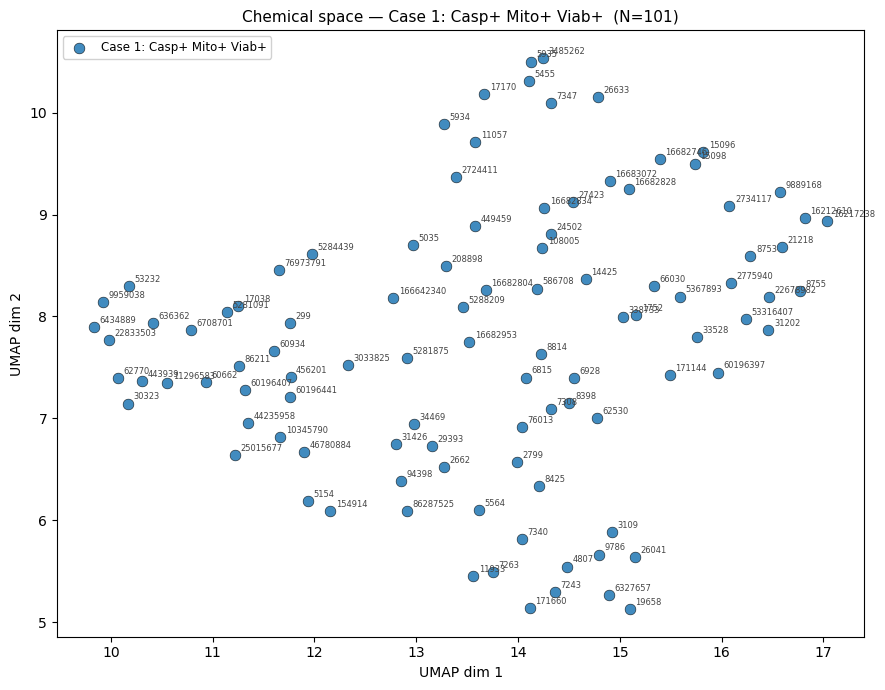

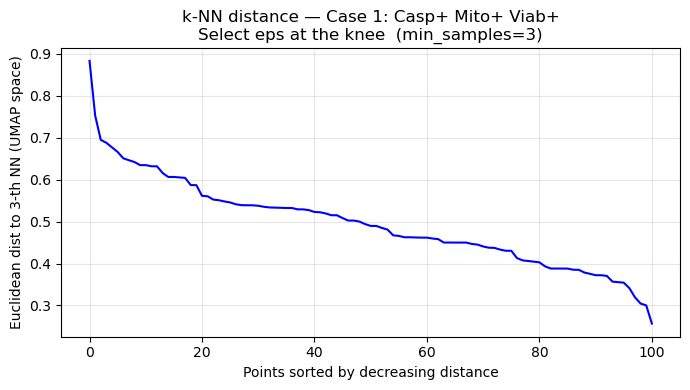

  Min=0.2567  Median=0.4896  Max=0.8833

DBSCAN (eps=0.45, min_samples=3)  →  11 clusters,  14 noise (13.9%)
            Count
Cluster 9      23
Noise          14
Cluster 6      10
Cluster 8      10
Cluster 2       9
Cluster 3       8
Cluster 0       6
Cluster 1       6
Cluster 10      5
Cluster 4       4
Cluster 5       3
Cluster 7       3
Fetching PubChem names — Case 1: Casp+ Mito+ Viab+...
  Cluster  0 (n=   6)  p-Nonylphenol  [CID 1752]
  Cluster  1 (n=   6)  Prodiamine  [CID 34469]
  Cluster  2 (n=   9)  Antioxidant 2246  [CID 8398]
  Cluster  3 (n=   8)  O-PHENYLENEDIAMINE  [CID 7243]
  Cluster  4 (n=   4)  thiram  [CID 5455]
  Cluster  5 (n=   3)  Ursol Olive 6G  [CID 7263]
  Cluster  6 (n=  10)  Benzododecinium chloride  [CID 8753]
  Cluster  7 (n=   3)  Crystal violet  [CID 11057]
  Cluster  8 (n=  10)  Tributyltin acrylate  [CID 16683072]
  Cluster  9 (n=  23)  DAUNORUBICIN HYDROCHLORIDE  [CID 62770]
  Cluster 10 (n=   5)  Fentin acetate  [CID 16682804]


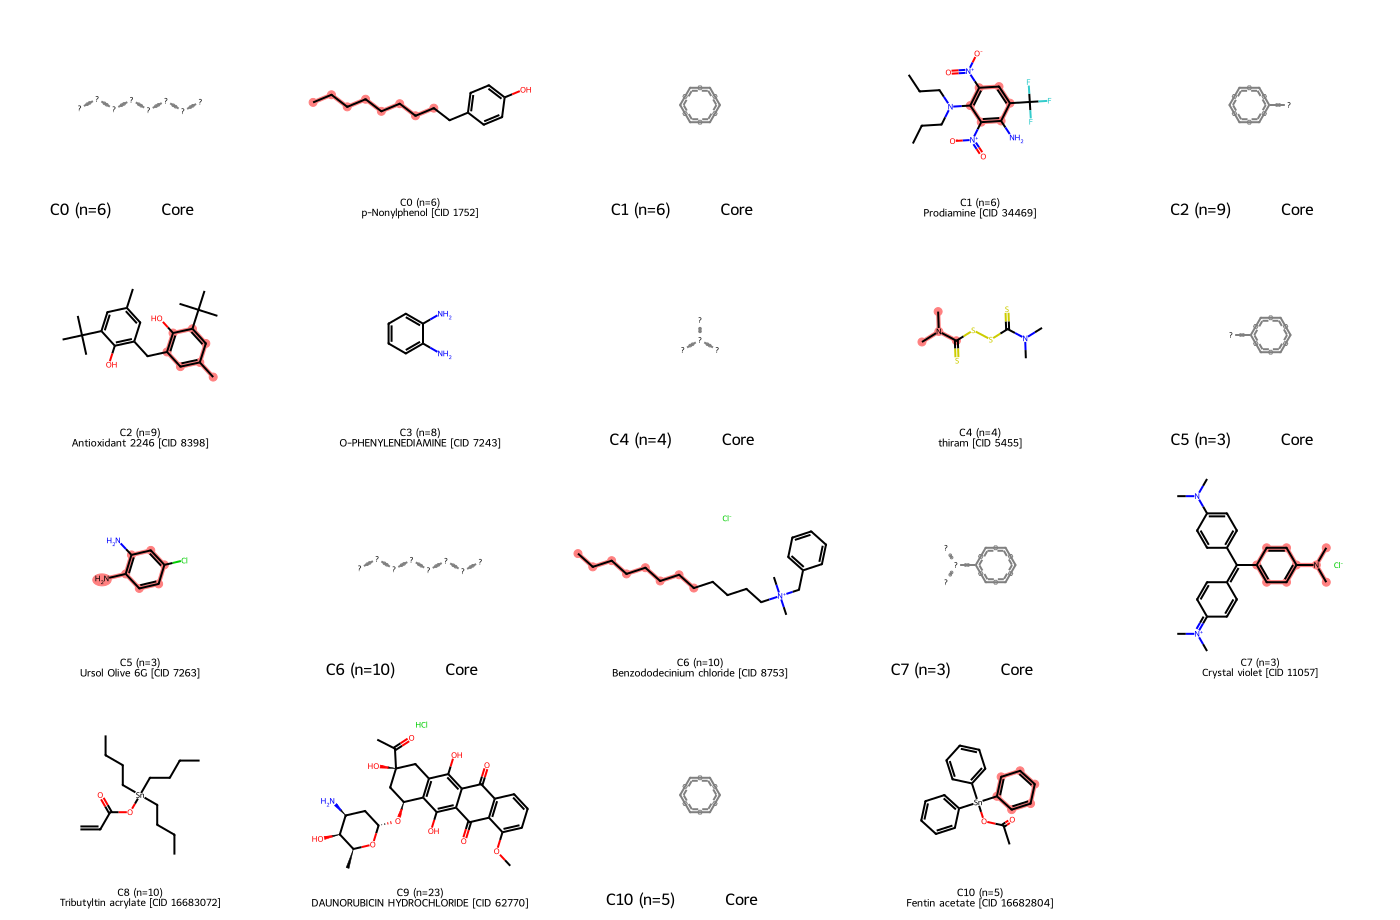

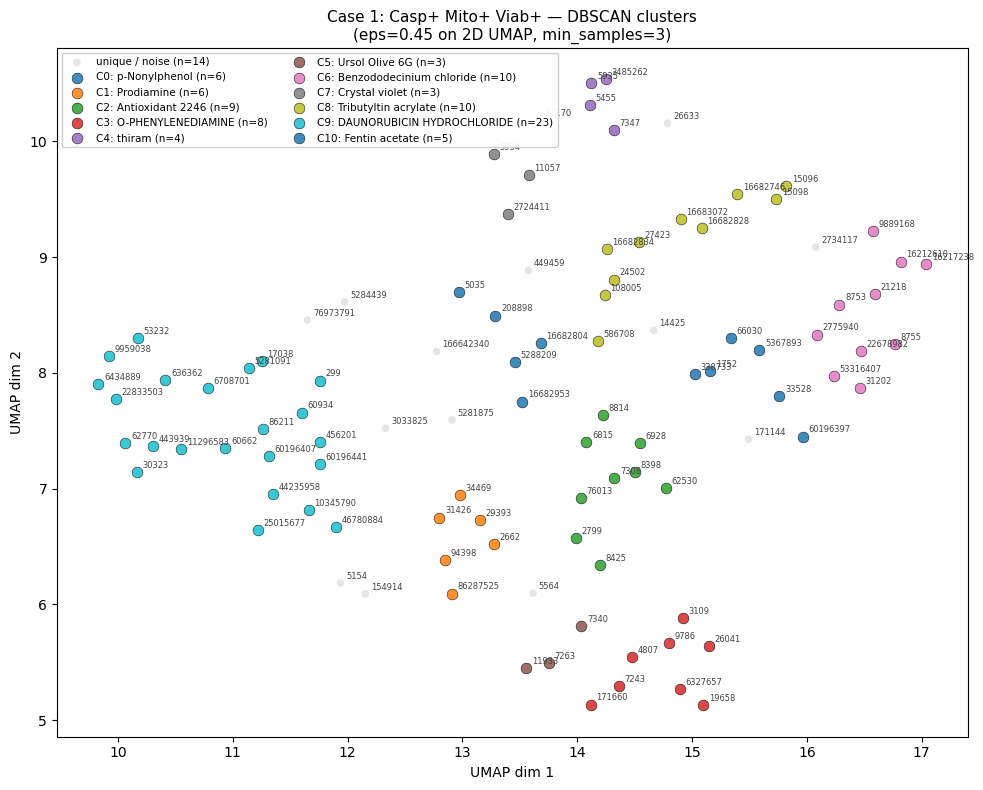

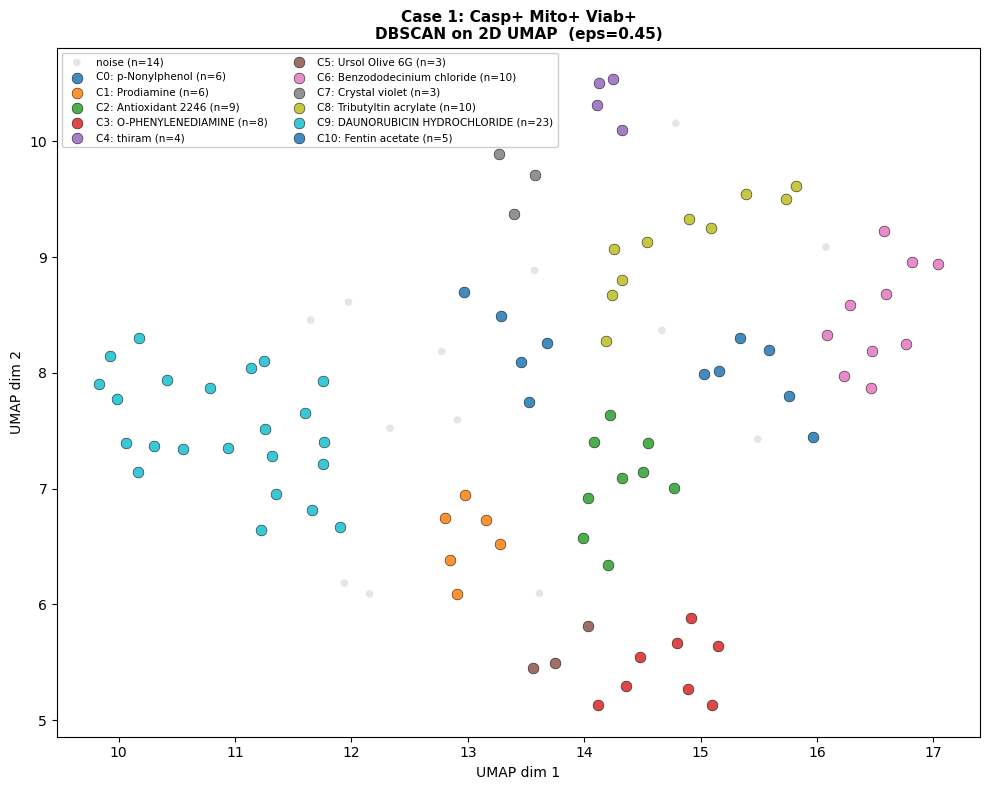

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casepase_viability_hepg2_comparisons/umap_dbscan_case1_caspase_active_mito_active_caspase_viability_active.png

  Case 2: Casp+ Mito+ Viab-
Unique CIDs: 11
Valid molecules: 11


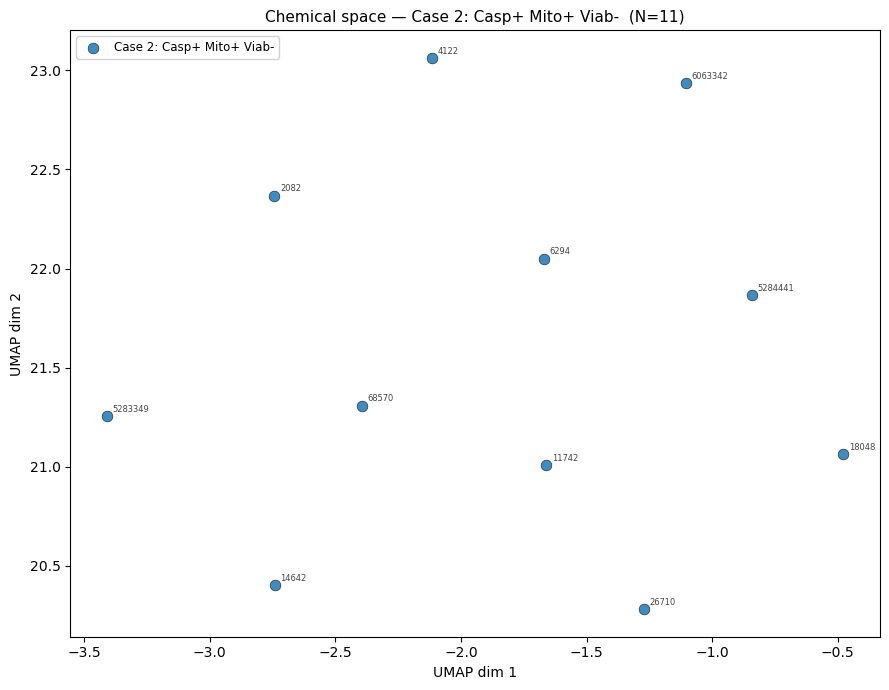

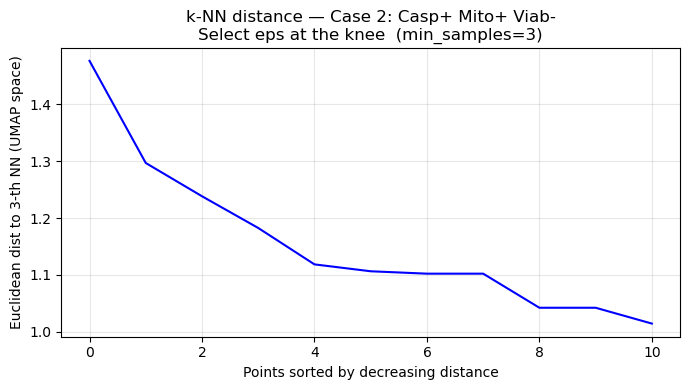

  Min=1.0144  Median=1.1064  Max=1.4765

DBSCAN (eps=0.45, min_samples=3)  →  0 clusters,  11 noise (100.0%)
       Count
Noise     11
Fetching PubChem names — Case 2: Casp+ Mito+ Viab-...
  No clusters found — all compounds are structurally unique.


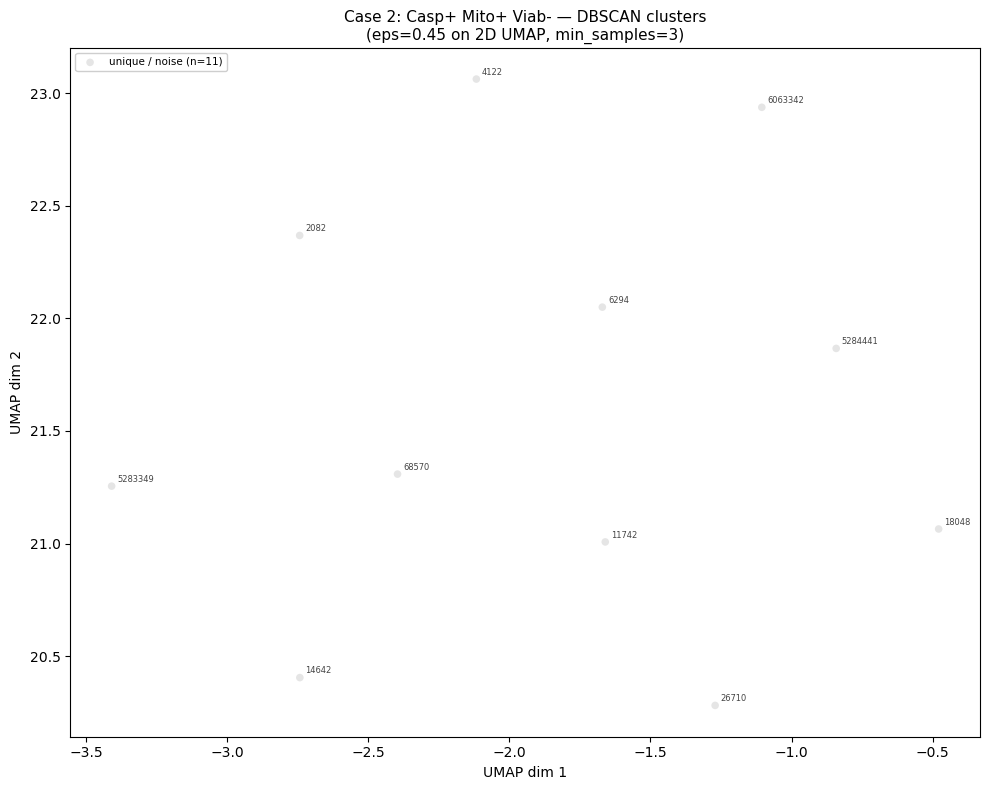

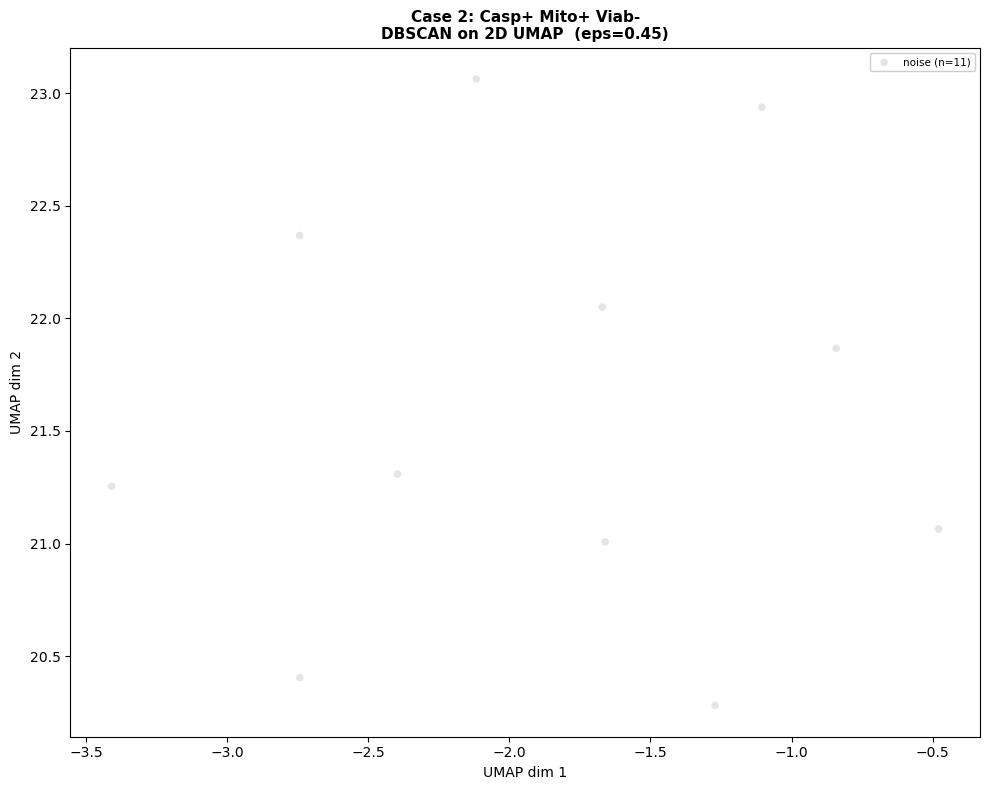

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casepase_viability_hepg2_comparisons/umap_dbscan_case2_caspase_active_mito_active_caspase_viability_inactive.png

  Case 3: Casp+ Mito- Viab+
Unique CIDs: 6
Valid molecules: 6
Too few molecules — skipping.

  Case 4: Casp+ Mito- Viab-
Unique CIDs: 5
Valid molecules: 5
Too few molecules — skipping.

  Case 5: Casp- Mito+ Viab+
Unique CIDs: 179
Valid molecules: 179


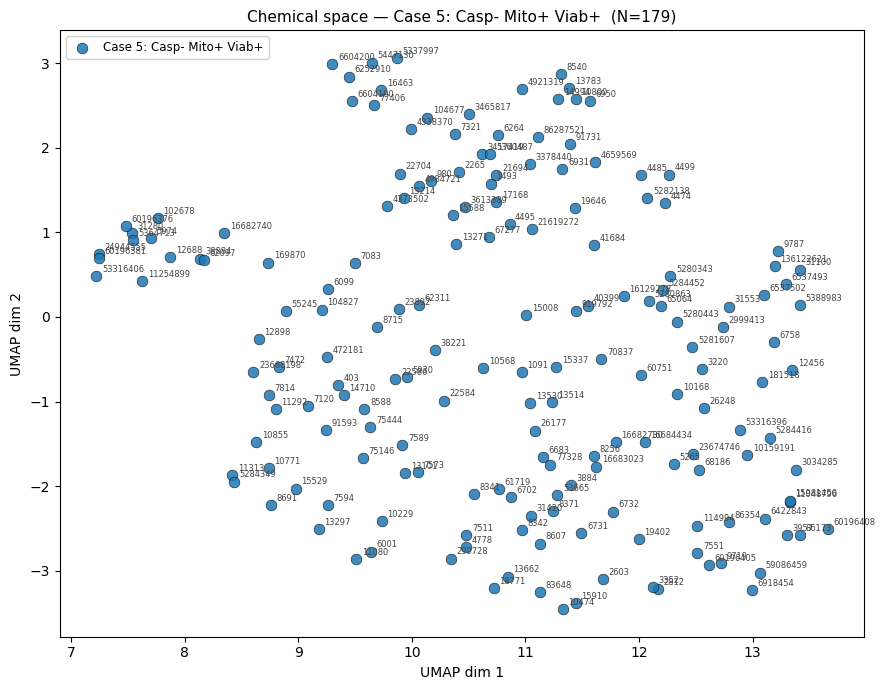

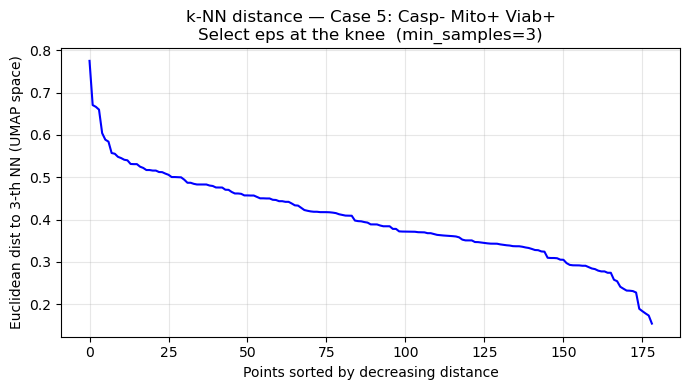

  Min=0.1538  Median=0.3885  Max=0.7754

DBSCAN (eps=0.45, min_samples=3)  →  10 clusters,  5 noise (2.8%)
           Count
Cluster 2     67
Cluster 1     38
Cluster 0     32
Cluster 4     13
Cluster 6      6
Cluster 7      6
Noise          5
Cluster 3      3
Cluster 5      3
Cluster 8      3
Cluster 9      3
Fetching PubChem names — Case 5: Casp- Mito+ Viab+...
  Cluster  0 (n=  32)  DTXSID50859469  [CID 10855]
  Cluster  1 (n=  38)  Aldifen  [CID 1493]
  Cluster  2 (n=  67)  purpurin anthraquinone  [CID 6683]
  Cluster  3 (n=   3)  PHENYLMERCURIC CHLORIDE  [CID 7511]
  Cluster  4 (n=  13)  DTXSID8049250  [CID 24944555]
  Cluster  5 (n=   3)  DMBA  [CID 6001]
  Cluster  6 (n=   6)  10800  [CID 10800]
  Cluster  7 (n=   6)  N-Phenylmaleimide  [CID 13662]
  Cluster  8 (n=   3)  berberine chloride  [CID 12456]
  Cluster  9 (n=   3)  HSDB 5079  [CID 23892]


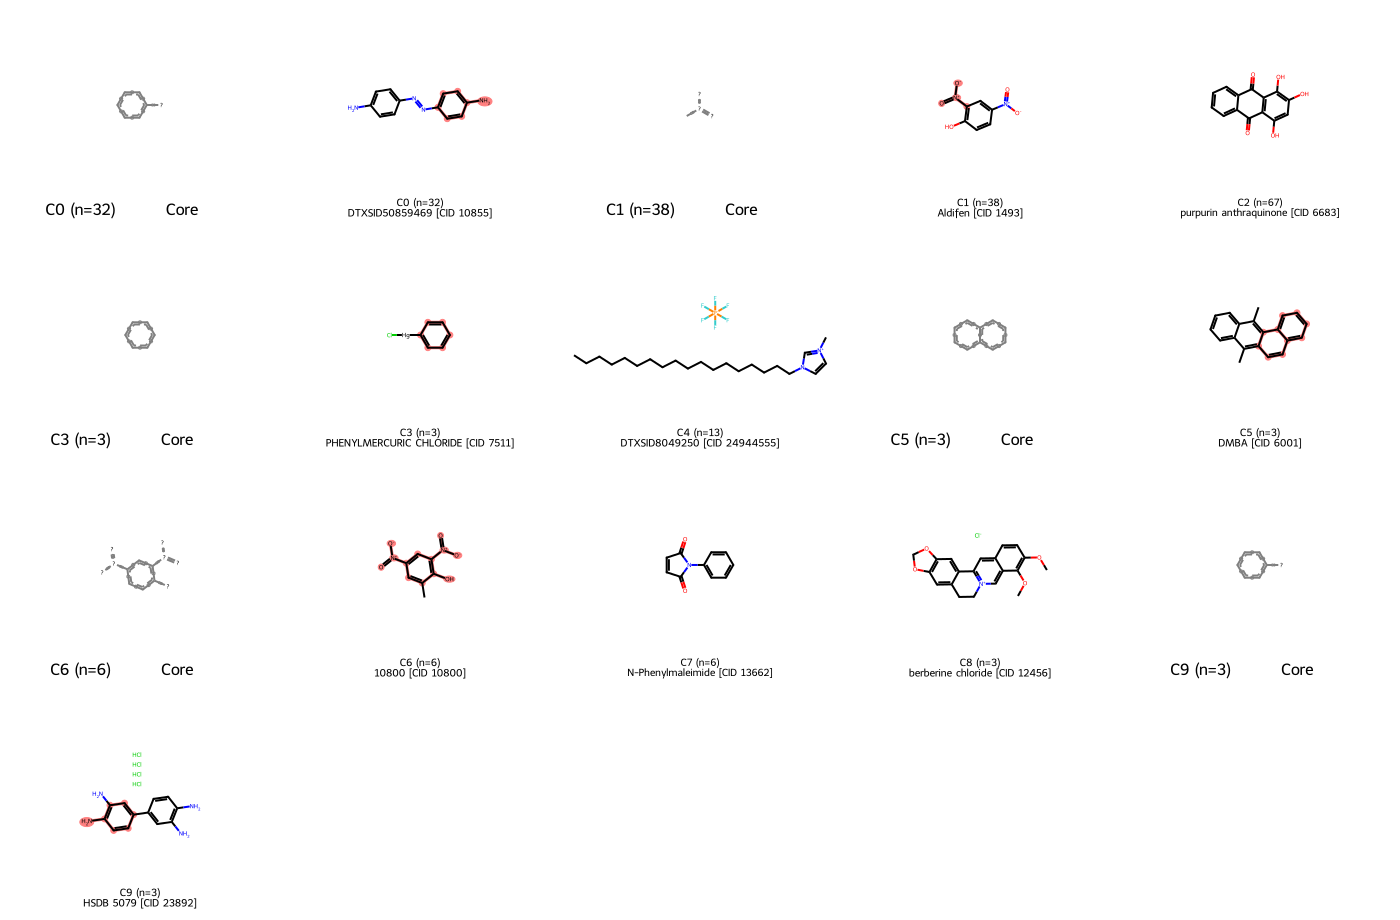

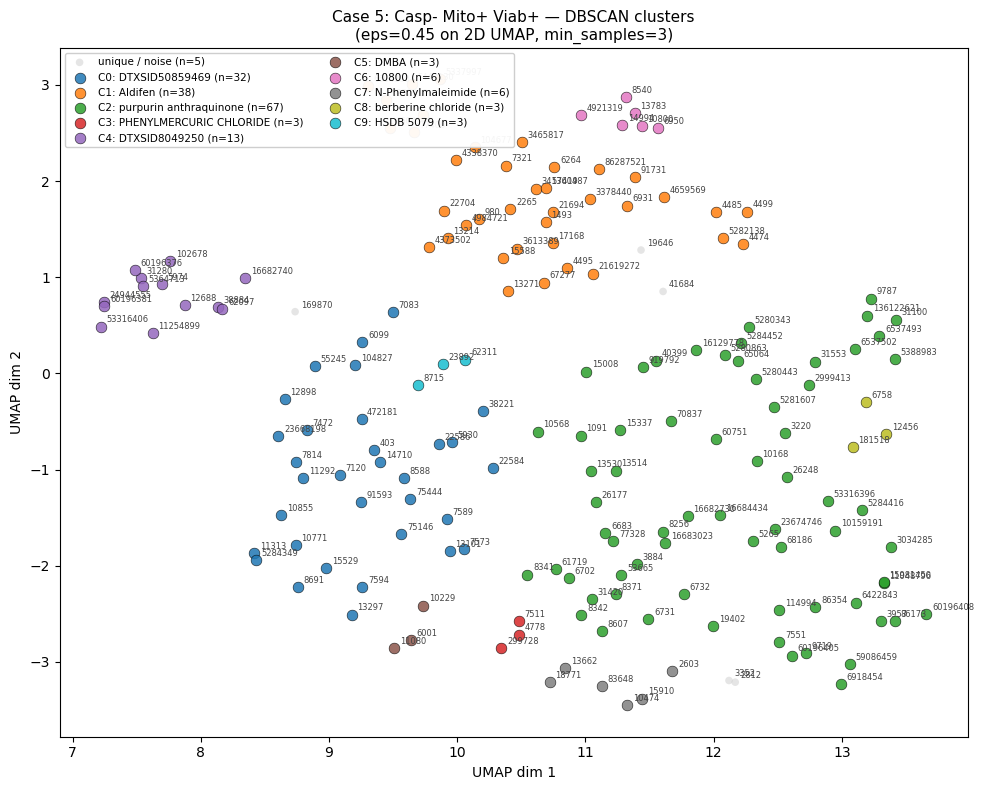

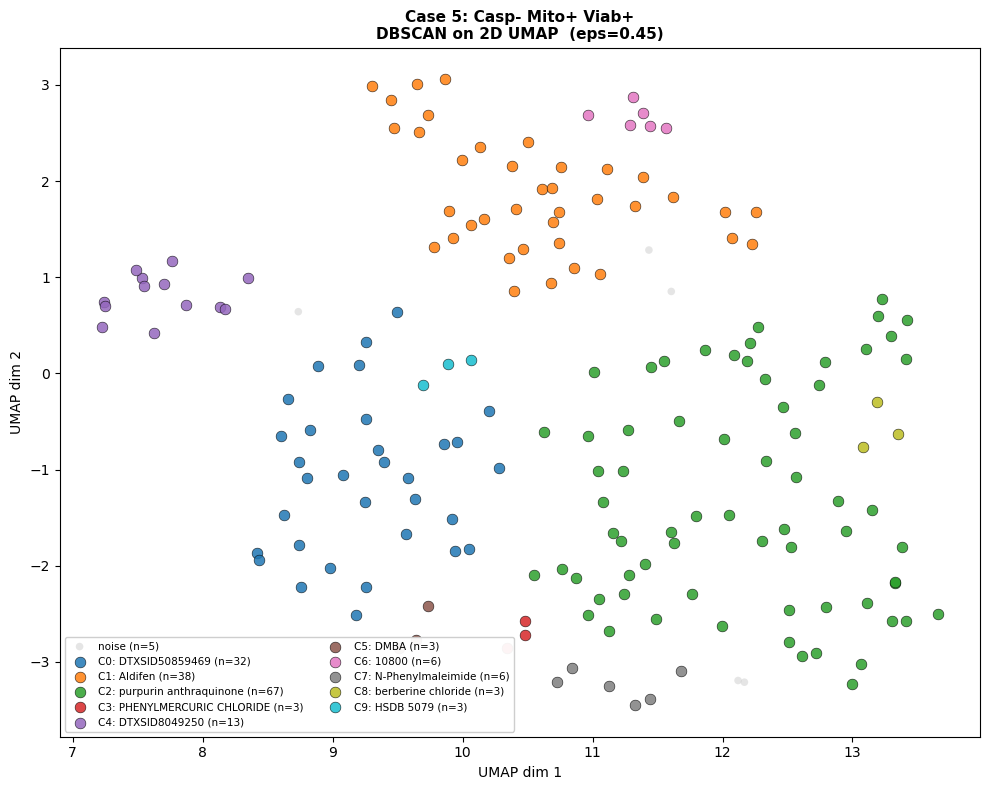

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casepase_viability_hepg2_comparisons/umap_dbscan_case5_caspase_inactive_mito_active_caspase_viability_active.png

  Case 6: Casp- Mito+ Viab-
Unique CIDs: 550
Valid molecules: 550


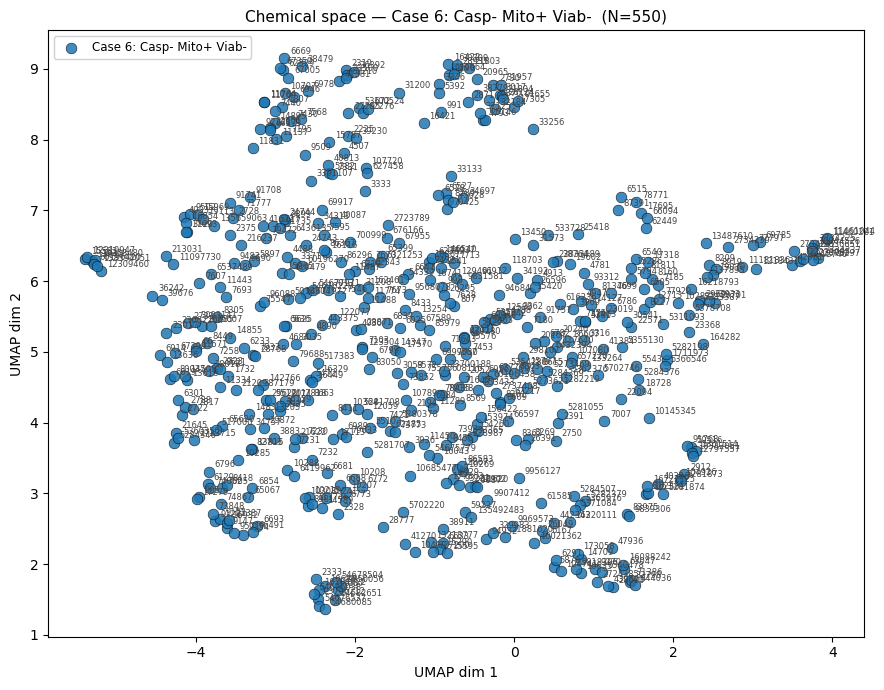

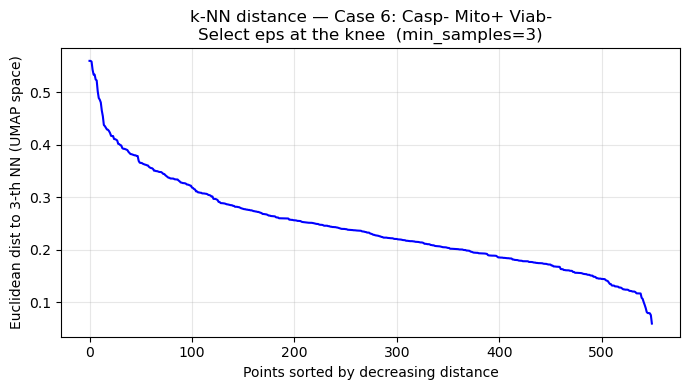

  Min=0.0590  Median=0.2303  Max=0.5596

DBSCAN (eps=0.45, min_samples=3)  →  6 clusters,  0 noise (0.0%)
           Count
Cluster 0    484
Cluster 1     26
Cluster 3     15
Cluster 2     11
Cluster 4      7
Cluster 5      7
Fetching PubChem names — Case 6: Casp- Mito+ Viab-...
  Cluster  0 (n= 484)  DIHEXYL PHTHALATE  [CID 6786]
  Cluster  1 (n=  26)  BROMOPHOS-ETHYL  [CID 20965]
  Cluster  2 (n=  11)  COUMACHLOR  [CID 54682651]
  Cluster  3 (n=  15)  cypermethrin  [CID 2912]
  Cluster  4 (n=   7)  Monocresyl diphenyl phosphate  [CID 6528]
  Cluster  5 (n=   7)  aldrin  [CID 12310947]


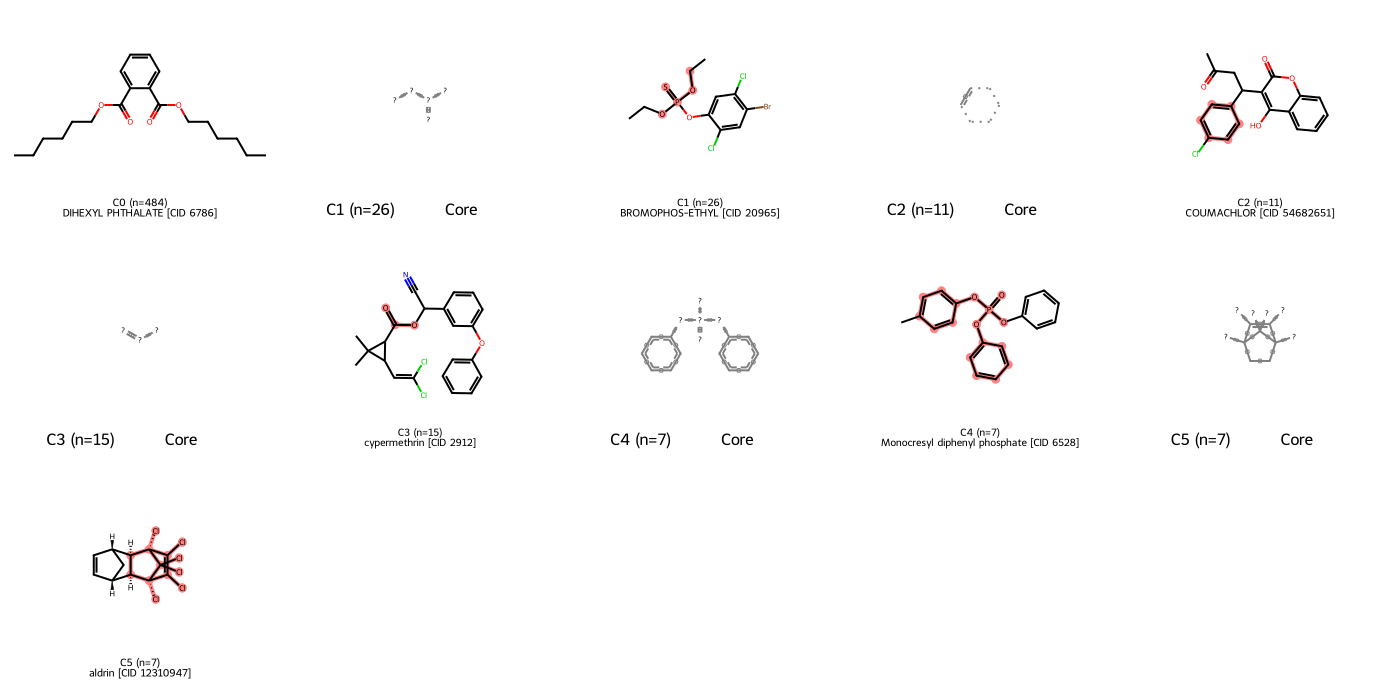

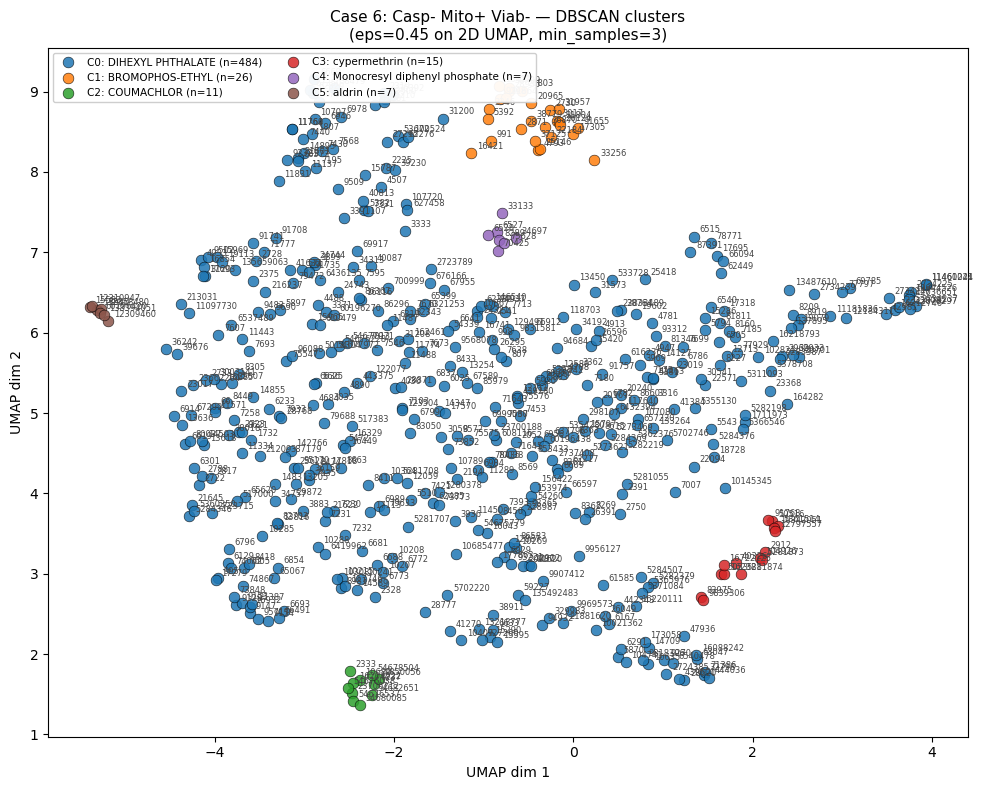

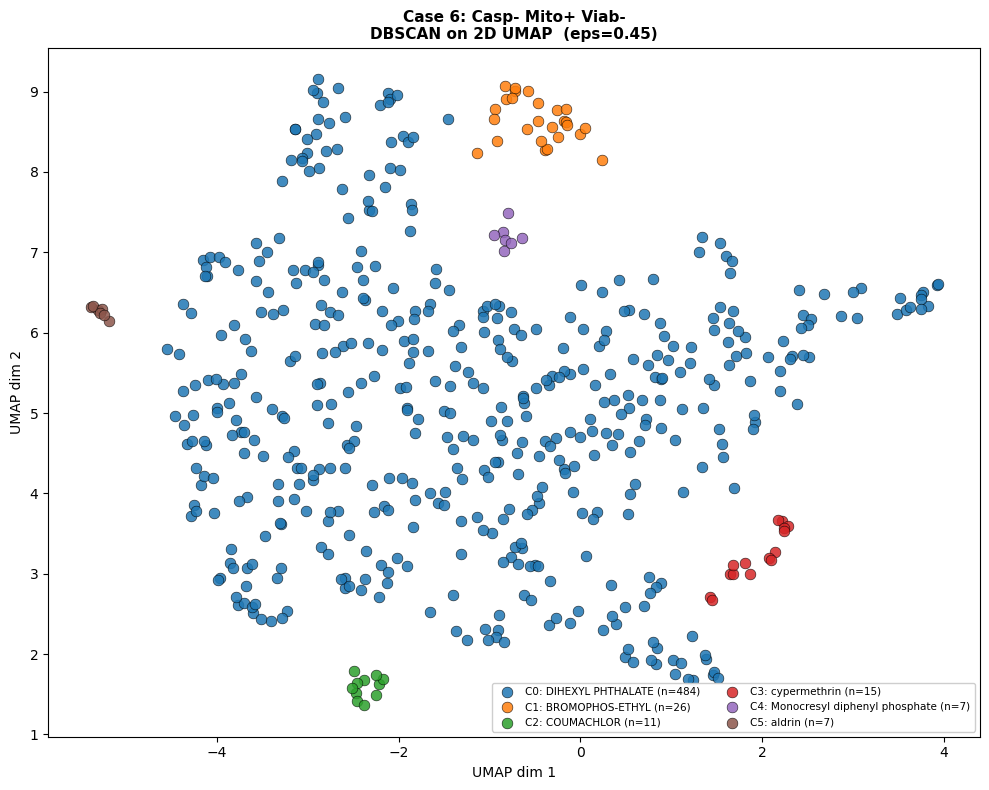

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casepase_viability_hepg2_comparisons/umap_dbscan_case6_caspase_inactive_mito_active_caspase_viability_inactive.png

  Case 7: Casp- Mito- Viab+
Unique CIDs: 17
Valid molecules: 17


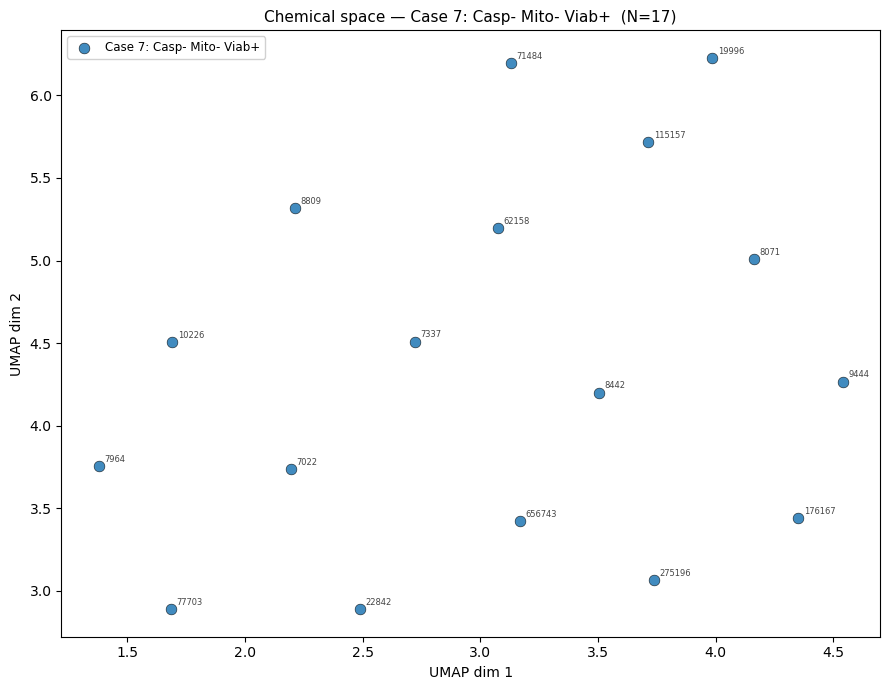

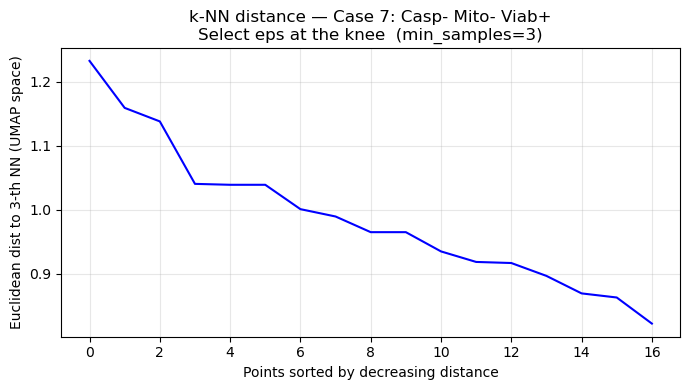

  Min=0.8224  Median=0.9653  Max=1.2330

DBSCAN (eps=0.45, min_samples=3)  →  0 clusters,  17 noise (100.0%)
       Count
Noise     17
Fetching PubChem names — Case 7: Casp- Mito- Viab+...
  No clusters found — all compounds are structurally unique.


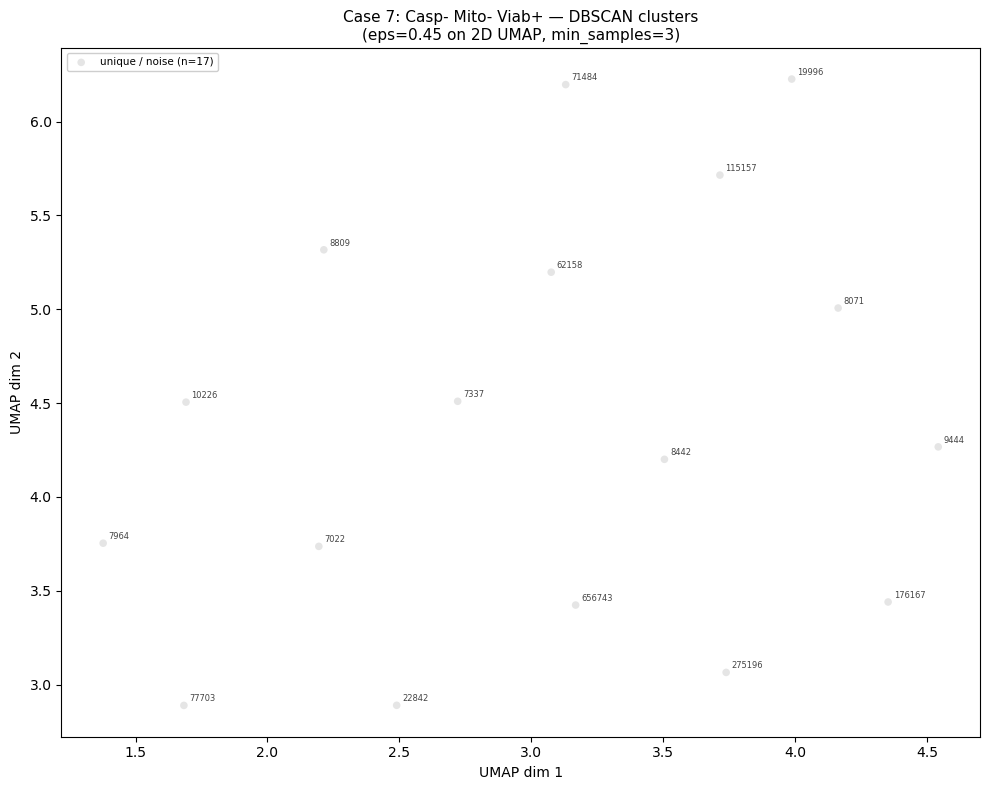

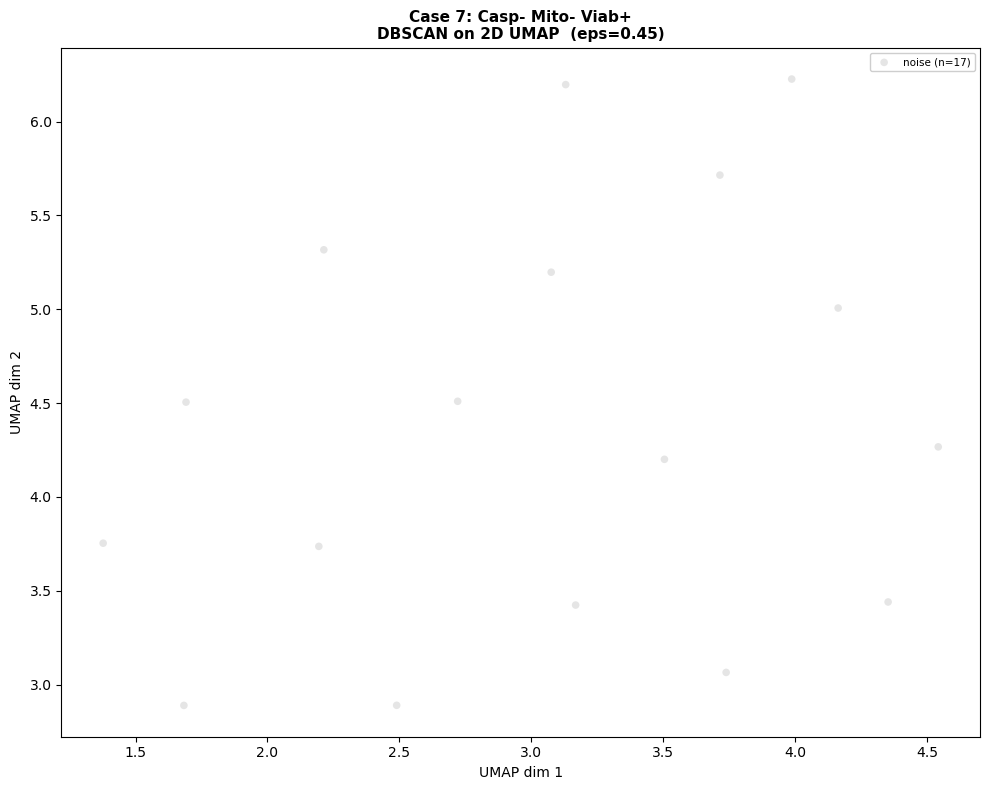

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casepase_viability_hepg2_comparisons/umap_dbscan_case7_caspase_inactive_mito_inactive_caspase_viability_active.png

  Case 8: Casp- Mito- Viab-
Unique CIDs: 2448


[16:08:43] WARNING: not removing hydrogen atom without neighbors


Valid molecules: 2448


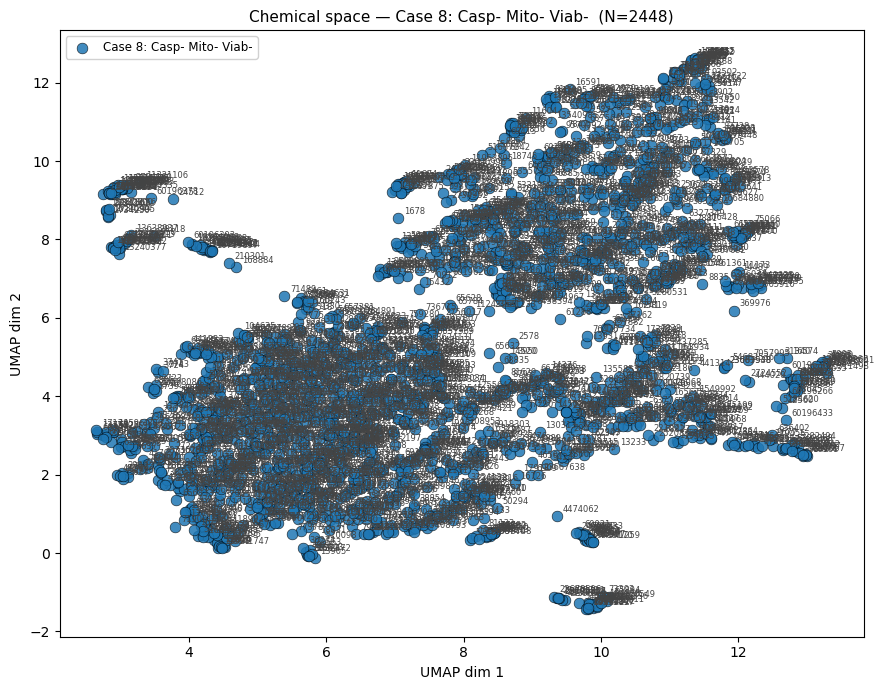

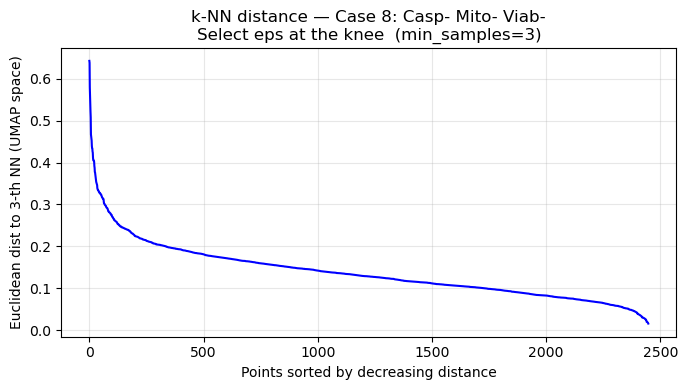

  Min=0.0159  Median=0.1285  Max=0.6427

DBSCAN (eps=0.45, min_samples=3)  →  6 clusters,  3 noise (0.1%)
           Count
Cluster 0   2331
Cluster 5     34
Cluster 2     26
Cluster 4     19
Cluster 3     18
Cluster 1     17
Noise          3
Fetching PubChem names — Case 8: Casp- Mito- Viab-...
  Cluster  0 (n=2331)  ETHYL BENZOATE  [CID 7165]
  Cluster  1 (n=  17)  Gatifloxacin  [CID 5379]
  Cluster  2 (n=  26)  cephalothin  [CID 6024]
  Cluster  3 (n=  18)  BPMBF4  [CID 2734180]
  Cluster  4 (n=  19)  DTXSID4049375  [CID 11009532]
  Cluster  5 (n=  34)  DTXSID7049342  [CID 11448496]


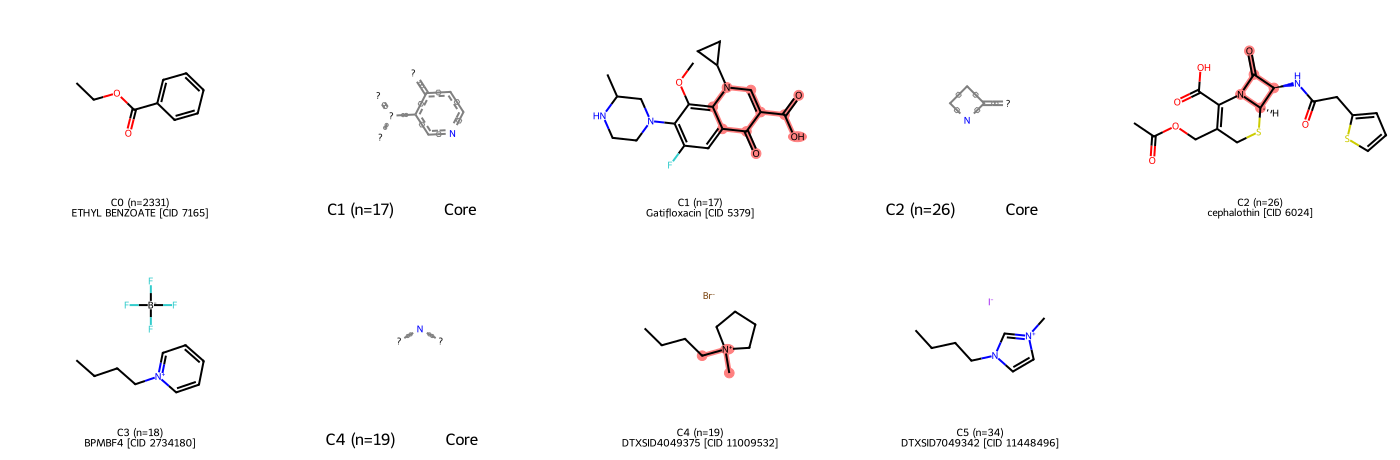

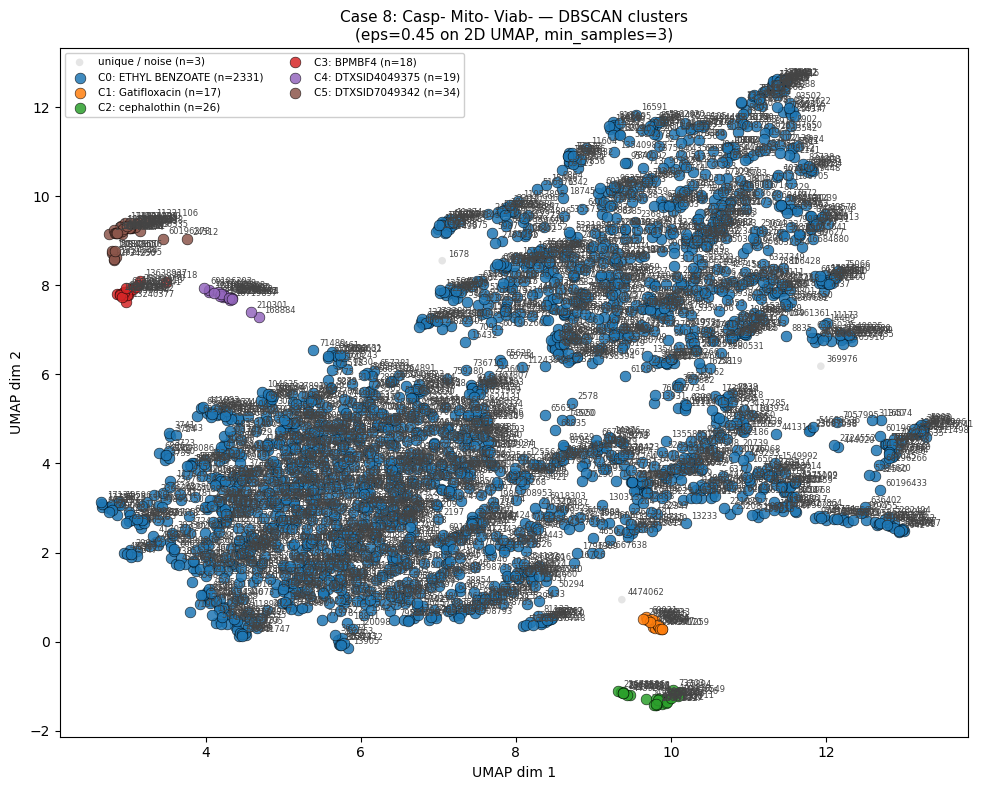

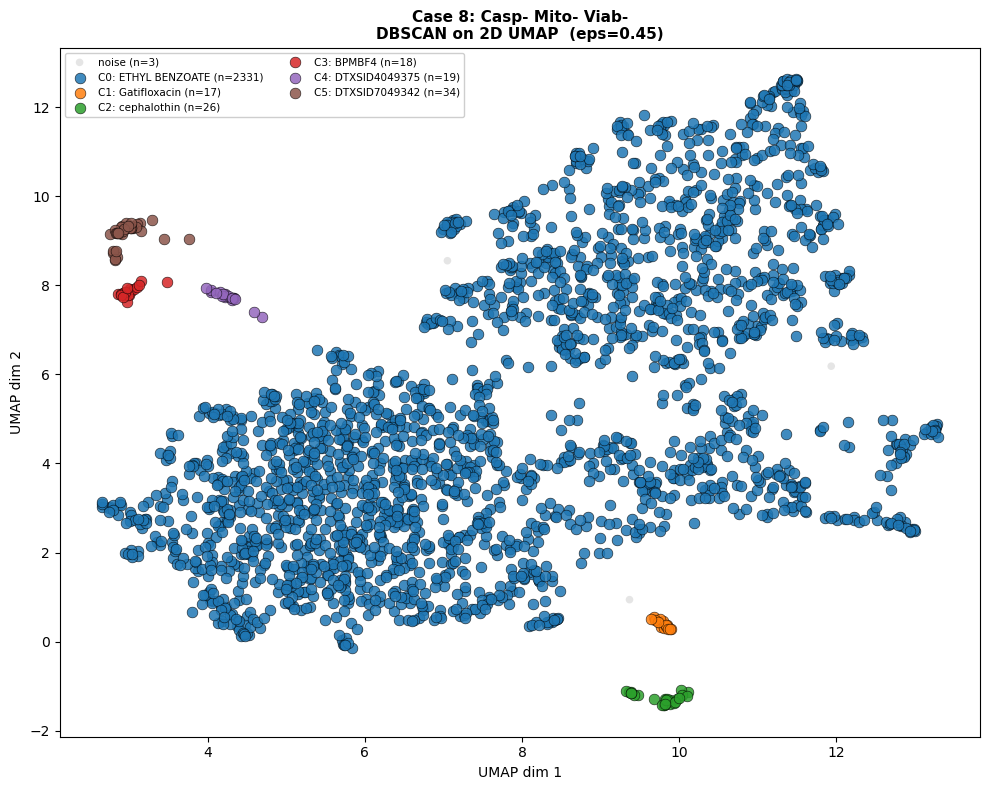

Saved → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/casepase_viability_hepg2_comparisons/umap_dbscan_case8_caspase_inactive_mito_inactive_caspase_viability_inactive.png



In [2]:
# ── EPS for DBSCAN in 2D UMAP space (Euclidean) ──────────────────────────────
# 1. Run this cell → inspect the k-NN distance plot per dataset.
# 2. Find the 'knee' (where the curve bends sharply).
# 3. Set EPS to that y-value and re-run.
# Typical range in 2D UMAP space: 0.3–0.7  (much smaller than Jaccard on FPs)
EPS         = 0.45   # <-- adjust after inspecting the k-NN plots below
MIN_SAMPLES = 3      # minimum cluster size

for label, fname in DATASETS:
    print('=' * 65)
    print(f'  {label}')
    print('=' * 65)

    # ── Load ──────────────────────────────────────────────────────────
    df = pd.read_csv(
        RESULTS + fname,
        usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'],
        low_memory=False, encoding=ENCODING
    ).dropna(subset=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'])
    df['PUBCHEM_CID'] = df['PUBCHEM_CID'].astype(int)
    df = df.drop_duplicates(subset='PUBCHEM_CID').reset_index(drop=True)
    print(f'Unique CIDs: {len(df)}')

    # ── Parse molecules + fingerprints ────────────────────────────────
    df['mol'] = df['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
        lambda s: Chem.MolFromSmiles(str(s)) if pd.notna(s) else None)
    df = df[df['mol'].notna()].reset_index(drop=True)
    fps_rdkit, fp_matrix = to_fp_matrix(df['mol'].tolist())
    df['fp'] = fps_rdkit
    N = len(df)
    print(f'Valid molecules: {N}')

    if N < 10:
        print('Too few molecules — skipping.\n')
        continue

    # ── UMAP: Jaccard on fingerprints → 2D ────────────────────────────
    emb = plot_umap(
        fp_matrix,
        labels   = [label] * N,
        title    = f'Chemical space — {label}  (N={N})',
        annotate = df['PUBCHEM_CID'],
    )
    df['umap_x'], df['umap_y'] = emb[:, 0], emb[:, 1]

    # ── k-NN distance plot on 2D UMAP coords (Euclidean) ─────────────
    knn_eps_plot(emb, MIN_SAMPLES, f'k-NN distance — {label}')

    # ── DBSCAN on 2D UMAP (Euclidean) ────────────────────────────────
    db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(emb)
    df['cluster'] = db.labels_
    n_cl    = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
    n_noise = (db.labels_ == -1).sum()
    print(f'\nDBSCAN (eps={EPS}, min_samples={MIN_SAMPLES})'
          f'  →  {n_cl} clusters,  {n_noise} noise ({100*n_noise/N:.1f}%)')

    comp = df.groupby('cluster').size().rename('Count').to_frame()
    comp.index = ['Noise' if i == -1 else f'Cluster {i}' for i in comp.index]
    print(comp.sort_values('Count', ascending=False).to_string())

    cl_names = draw_cluster_reps(df, title=label)
    umap_by_cluster(df, cl_names,
                    title=f'{label} — DBSCAN clusters\n'
                          f'(eps={EPS} on 2D UMAP, min_samples={MIN_SAMPLES})')

    fig, ax = plt.subplots(figsize=(10, 8))
    cmap = plt.cm.tab10
    noise_df = df[df['cluster'] == -1]
    if len(noise_df):
        ax.scatter(noise_df['umap_x'], noise_df['umap_y'], c='#cccccc',
                   s=30, alpha=0.5, edgecolors='none',
                   label=f'noise (n={len(noise_df)})')
    for cl in sorted(c for c in df['cluster'].unique() if c != -1):
        sub  = df[df['cluster'] == cl]
        name = cl_names.get(cl, f'Cluster {cl}')
        ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
                   s=60, edgecolors='black', linewidths=0.4, alpha=0.85,
                   label=f'C{cl}: {name} (n={len(sub)})')
    ax.legend(fontsize=7.5, ncol=2, framealpha=0.95)
    ax.set_title(f'{label}\nDBSCAN on 2D UMAP  (eps={EPS})',
                 fontsize=11, fontweight='bold')
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout()
    slug = fname.replace('.csv', '')
    out  = RESULTS + f'umap_dbscan_{slug}.png'
    plt.savefig(out, dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'Saved → {out}\n')
